In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import os
pi_cation_dir = os.getcwd()
os.chdir('../')
from edautils.plot import ternary_ax, ternary
from edautils.plot import calc_portion, energy_bar_ax
from edautils.plot import kdeplot, kdeplot_norm
from edautils.plot import violin
from edautils.plot import pie
from edautils.plot import plot

from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

os.chdir(pi_cation_dir)

# Heteroatom vs Pure Aromatic

# Classification

In [2]:
plt.rcParams.update({
    # 'font.size': 12,
    # 'axes.titlesize': 12,
    'font.family': 'sans-serif',
    'font.sans-serif': ['Lato'],
})

COLOR_MAPS = {
    "TOTAL": '#666666',
    "CT": '#b80058',
    "DISP": "#d95f02",
    "ELEC": '#5954d6',
    "POL": '#1b9e77',
    "PAULI": '#ebac23',
    'FRZ': '#a6cee3'
}

df = pd.read_csv('pi_cation_EDA.csv').iloc[:, 1:]
print('# Total pairs:', len(df))
print('# Repulsive pairs:', len(df.query('TOTAL > 0')))
print('# Attractive pairs:', len(df.query('TOTAL < 0')))

# CLS_DISP
df['DISP'] = np.where(np.isnan(df['DISP'].values), df['CLS_DISP'], df['DISP'])
processed_df = df.query('TOTAL < 0').drop(columns=['resnr_lig', 'restype_lig', 'reschain_lig', 'PREPARATION'])

processed_df["group"] = pd.NA
processed_df["group1"] = pd.NA
processed_df["group2"] = pd.NA

# Total pairs: 1402
# Repulsive pairs: 19
# Attractive pairs: 1383


In [3]:
df_aromatic_lig = processed_df.query("protcharged == True")
df_aromatic_prot = processed_df.query("protcharged == False")

hetrocyclic_prot = []
carbocyclic_prot = []


for index, row in df_aromatic_prot.iterrows():
    if row['restype'] == 'HIS' or row['restype'] == 'TRP':
        hetrocyclic_prot.append(index)
    if row['restype'] == 'TYR' or row['restype'] == 'PHE':
        carbocyclic_prot.append(index)


from edautils.fragment import find_rings_old
dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'

hetrocyclic_lig = []
carbocyclic_lig = []

hetrocyclic_atoms = []
carbocyclic_atoms = []

errs = []

for index, row in df_aromatic_lig.iterrows():
    aromatic = True
    temp_atomlist = []
    ligand = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf")
    mol = Chem.SDMolSupplier(ligand, removeHs=False, sanitize=True)[0]
    ring_list = find_rings_old(mol, find_hetero_rings=False, find_small_rings=False) # only aromatic rings, idx numbers in OpenBabel 1 lower than Plip

    lig_idx_list = row['lig_idx_list'].split()
    lig_idx_set = set([int(id) - 1 for id in lig_idx_list])
    ring_temp = [s for s in ring_list if lig_idx_set & s]
    
    try:
        for idx in ring_temp[0]:
            atom = mol.GetAtomWithIdx(idx)
            symbol = atom.GetSymbol()
            temp_atomlist.append(symbol)
            if not symbol == 'C':
                aromatic = False

        if aromatic:
            carbocyclic_lig.append(index)
            carbocyclic_atoms.append((index, temp_atomlist)) # keep the list of atoms
        else:
            hetrocyclic_lig.append(index)
            hetrocyclic_atoms.append((index, temp_atomlist)) # keep the list of atoms
    except Exception as e:
        for idx in lig_idx_set:
            atom = mol.GetAtomWithIdx(idx)
            symbol = atom.GetSymbol()
            temp_atomlist.append(symbol)
        errs.append([index, temp_atomlist])

processed_df.loc[hetrocyclic_prot, "group"] = "Hetero Prot"
processed_df.loc[hetrocyclic_lig, "group"] = "Hetero Lig"
processed_df.loc[carbocyclic_prot, "group"] = "Carbo Prot"
processed_df.loc[carbocyclic_lig, "group"] = "Carbo Lig"

carbocyclic = carbocyclic_prot + carbocyclic_lig
hetrocyclic = hetrocyclic_prot + hetrocyclic_lig

processed_df.loc[hetrocyclic, "group1"] = "Heterocyclic"
processed_df.loc[carbocyclic, "group1"] = "Carbocyclic"

prot_cat = hetrocyclic_lig + carbocyclic_lig
lig_cat = hetrocyclic_prot + carbocyclic_prot

processed_df.loc[prot_cat, "group2"] = "Cation Prot"
processed_df.loc[lig_cat, "group2"] = "Cation Lig"

# for x, subdf in processed_df.groupby("group"):
#     print(x, subdf.shape[0], subdf['TOTAL'].min())

print('\n')
for x, subdf in processed_df.groupby("group1"):
    print(x, subdf.shape[0], subdf['TOTAL'].min())

print('\n')
for x, subdf in processed_df.groupby("group2"):
    print(x, subdf.shape[0], subdf['TOTAL'].min())

errPDBID = [err[0] for err in errs]
errs



Carbocyclic 774 -165.7308
Heterocyclic 602 -153.8948


Cation Lig 329 -63.5955
Cation Prot 1047 -165.7308


[[103, ['C', 'C', 'O', 'C', 'C']],
 [604, ['C', 'C', 'C', 'N', 'C']],
 [859, ['C', 'C', 'C', 'N', 'C']],
 [1133, ['C', 'C', 'C', 'C', 'C', 'C']],
 [1207, ['C', 'C', 'O', 'C', 'C']],
 [1221, ['C', 'C', 'C', 'N', 'C']],
 [1340, ['C', 'C', 'C', 'S', 'N']]]

In [4]:
components = [
    ('TOTAL', 'TOTAL', 'Total'),
    ('MOD_PAULI', 'PAULI', 'Pauli'),
    ('CLS_ELEC', 'CLS_ELEC', 'Electrostatics'),
    ('DISP', 'DISP', 'Dispersion'),
    ('POLARIZATION', 'POL', 'Polarization'),
    ('CHARGE_TRANSFER', 'CT', 'Charge Transfer')
]

include_all = True
for c, label, pp in components:
    line = f'{pp}'
    if include_all:
        line += f'${np.mean(processed_df[c]):.2f}\\ ({np.median(processed_df[c]):.2f})$'
    for x in ["Heterocyclic", "Carbocyclic"]:
        data = processed_df.query(f'group1 == "{x}"')[c]
        line += f' & ${np.mean(data):.2f}\\ ({np.median(data):.2f})$'
    for x in ["Cation Prot", "Cation Lig"]:
        data = processed_df.query(f'group2 == "{x}"')[c]
        line += f' & ${np.mean(data):.2f}\\ ({np.median(data):.2f})$'
    line += ' \\\\'
    print(line)

Total$-40.17\ (-37.45)$ & $-39.20\ (-39.51)$ & $-41.13\ (-36.73)$ & $-41.79\ (-38.02)$ & $-35.50\ (-36.30)$ \\
Pauli$19.74\ (16.27)$ & $20.41\ (16.62)$ & $19.21\ (15.87)$ & $19.24\ (15.25)$ & $21.32\ (19.27)$ \\
Electrostatics$-21.02\ (-18.55)$ & $-19.74\ (-18.40)$ & $-22.18\ (-18.81)$ & $-20.76\ (-17.08)$ & $-22.23\ (-22.31)$ \\
Dispersion$-18.56\ (-17.86)$ & $-20.29\ (-20.32)$ & $-17.24\ (-16.40)$ & $-18.54\ (-17.45)$ & $-18.68\ (-18.59)$ \\
Polarization$-16.78\ (-14.36)$ & $-16.08\ (-14.36)$ & $-17.33\ (-14.37)$ & $-18.25\ (-15.73)$ & $-12.12\ (-12.25)$ \\
Charge Transfer$-3.55\ (-2.87)$ & $-3.50\ (-2.77)$ & $-3.58\ (-2.92)$ & $-3.47\ (-2.68)$ & $-3.79\ (-3.53)$ \\


# Violin + Bar Plot

## Cation on Protein vs Ligand

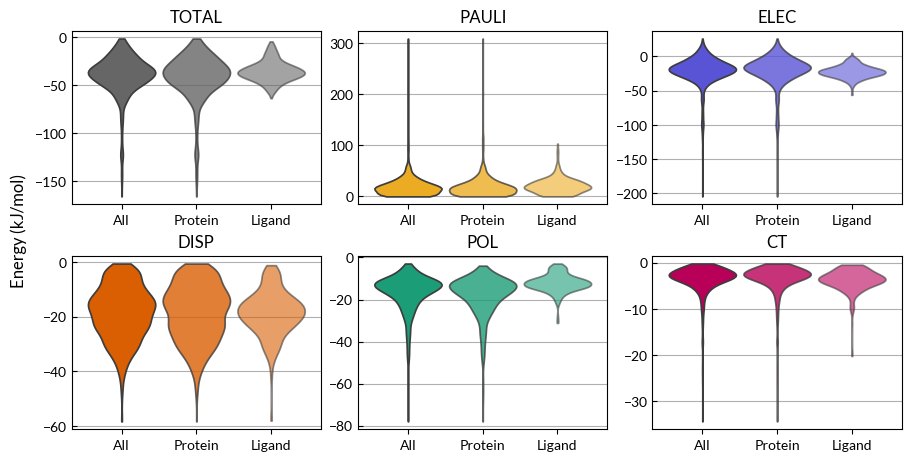

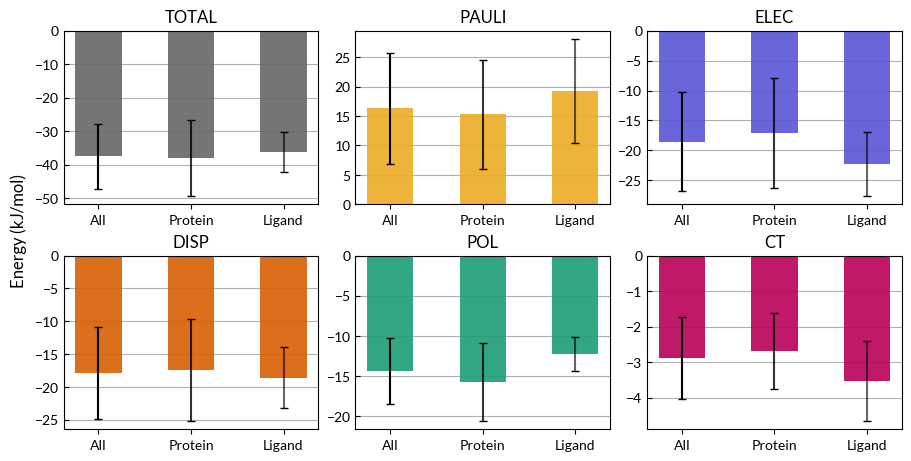

In [7]:
from matplotlib import font_manager
font_manager.fontManager.addfont("../edautils/fonts/Lato/Lato-Regular.ttf")
font_manager.fontManager.addfont("../edautils/fonts/Helvetica/Helvetica.ttf")

group_name = 'group2'
groups = ['ALL', 'Cation Prot', 'Cation Lig']
labels = ['All', 'Protein', 'Ligand']

fig, axes = plt.subplots(2, 3, figsize=(9, 4.5), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='violin')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/violin_cation.png')

fig, axes = plt.subplots(2, 3, figsize=(9, 4.5), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='bar')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/bar_cation.png')

## Heterocyclic vs Carbocyclic Rings

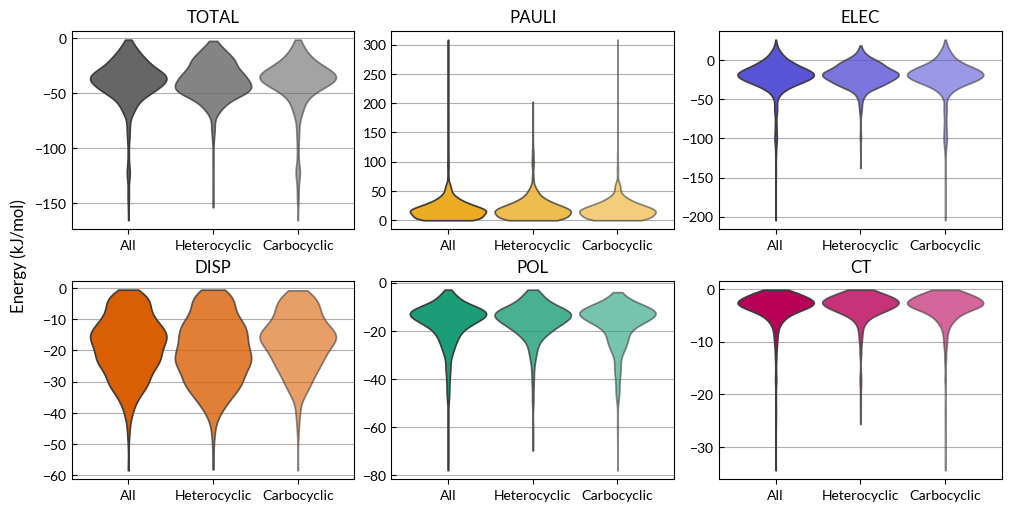

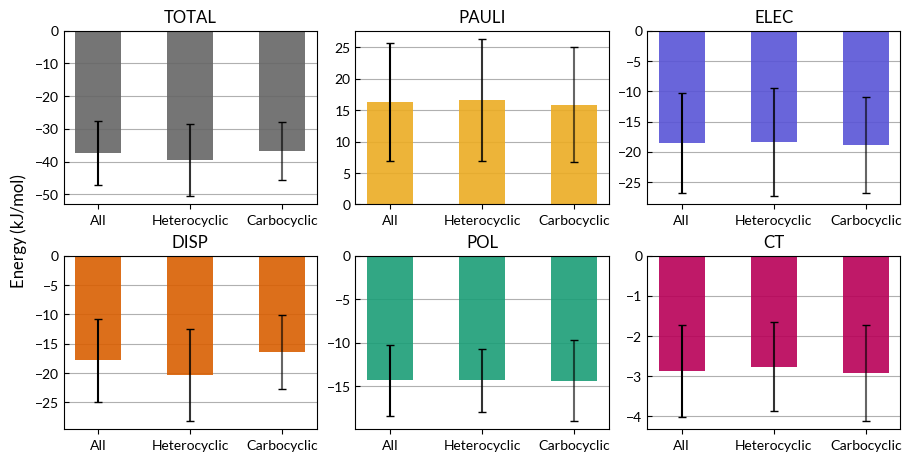

In [8]:
group_name = 'group1'
groups = ['ALL', 'Heterocyclic', 'Carbocyclic']
labels = ['All', 'Heterocyclic', 'Carbocyclic']

fig, axes = plt.subplots(2, 3, figsize=(10, 5), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='violin')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/violin_ring.png')

fig, axes = plt.subplots(2, 3, figsize=(9, 4.5), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='bar')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/bar_ring.png')

# Pie Plot

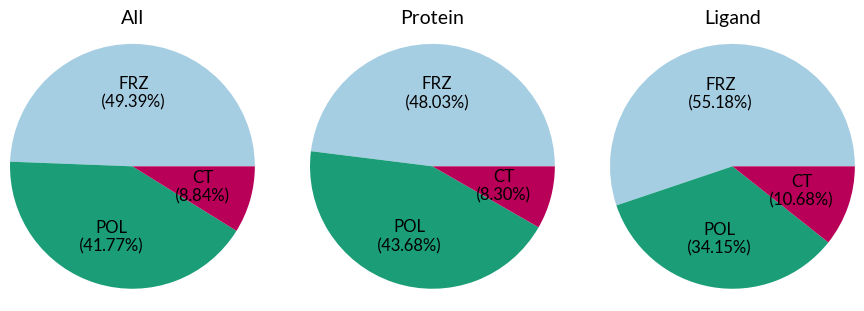

In [10]:
group_name = 'group2'
groups = ['ALL', 'Cation Prot', 'Cation Lig']
labels = ['All', 'Protein', 'Ligand']

fig, axes = plt.subplots(1, 3, constrained_layout=True, figsize=(9, 3))
pie(axes, group_name, groups, labels, processed_df)
fig.savefig('Visualizations/pie_cation.png')

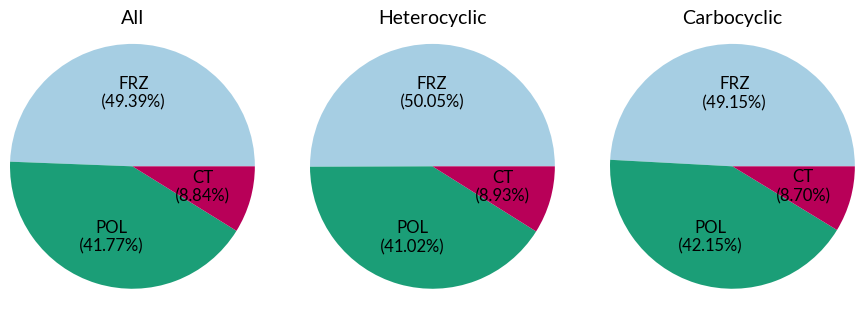

In [11]:
group_name = 'group1'
groups = ['ALL', 'Heterocyclic', 'Carbocyclic']
labels = ['All', 'Heterocyclic', 'Carbocyclic']

fig, axes = plt.subplots(1, 3, constrained_layout=True, figsize=(9, 3))
pie(axes, group_name, groups, labels, processed_df)
fig.savefig('Visualizations/pie_ring.png')

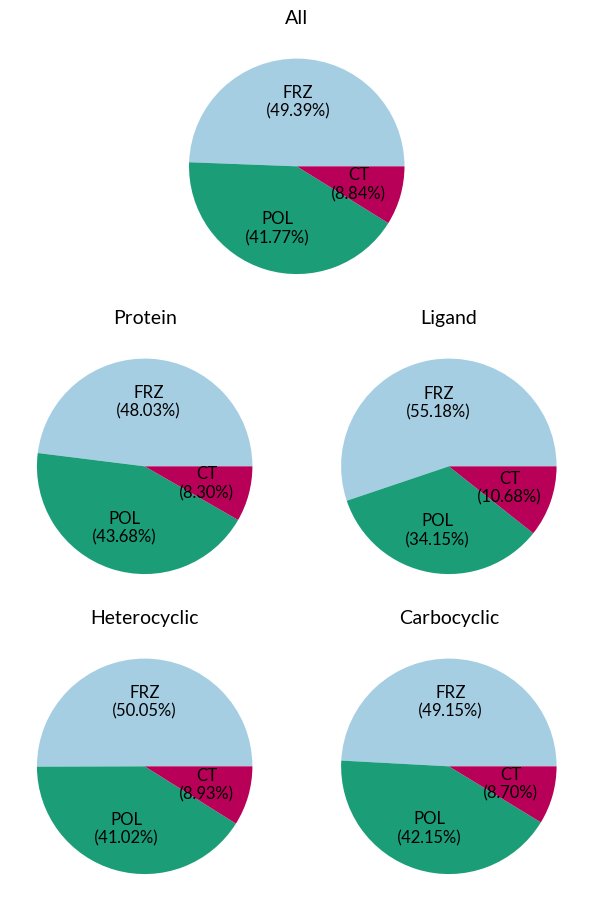

In [12]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(6, 9), constrained_layout=True)
gs = GridSpec(3, 2, figure=fig)

ax_all   = fig.add_subplot(gs[0, :])
ax_cp    = fig.add_subplot(gs[1, 0])
ax_cl    = fig.add_subplot(gs[1, 1])
ax_het   = fig.add_subplot(gs[2, 0])
ax_carb  = fig.add_subplot(gs[2, 1])

pie(ax_all, 'group1', ['ALL'], ['All'],  processed_df)

pie(ax_cp, 'group2', ['Cation Prot'], ['Protein'], processed_df)
pie(ax_cl, 'group2', ['Cation Lig'], ['Ligand'], processed_df)

pie(ax_het, 'group1', ['Heterocyclic'], ['Heterocyclic'], processed_df)
pie(ax_carb,'group1', ['Carbocyclic'], ['Carbocyclic'], processed_df)
plt.savefig('Visualizations/pie_all.png')

# Protein and ligand combined

# Ternary Plots

In [18]:
dfs = df_aromatic


dfs = [df_aromatic, df_hetratom]
labels = ['Pure Atomatic', 'Heteroatom']

cmap_range = [-100, 0]
type = 'frz_orb_disp'

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc = plot('ternary', (labels[0], 'a', type), dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), dfs[1], axes[1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig("Visualizations/ternary_1.png")

type = 'elec_orb_disp'

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc = plot('ternary', (labels[0], 'a', type), dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), dfs[1], axes[1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

type = 'frz_pol_ct'

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc = plot('ternary', (labels[0], 'a', type), dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), dfs[1], axes[1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig("Visualizations/ternary_2.png")


NameError: name 'df_aromatic' is not defined

# Tyrosine H-Bonding?

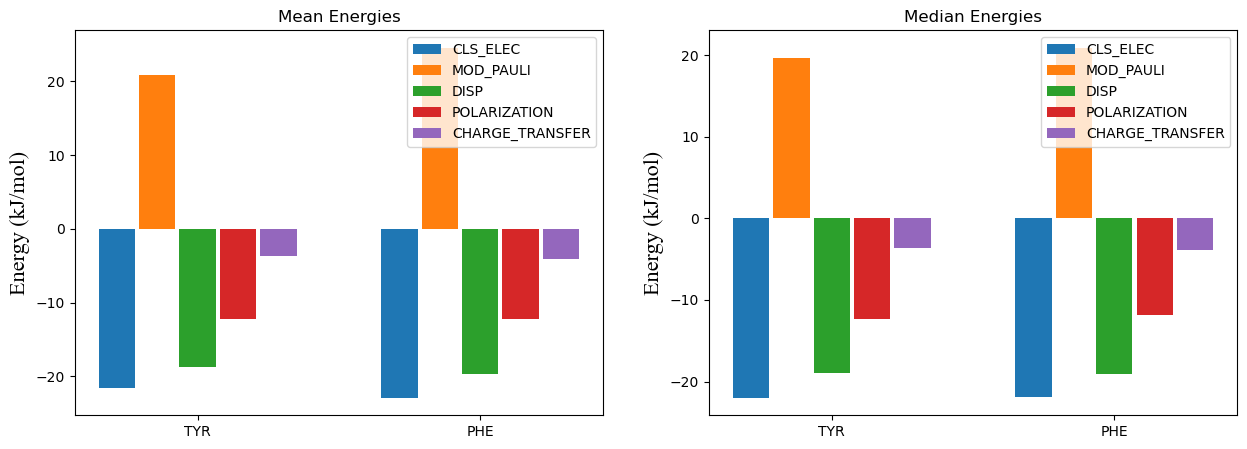

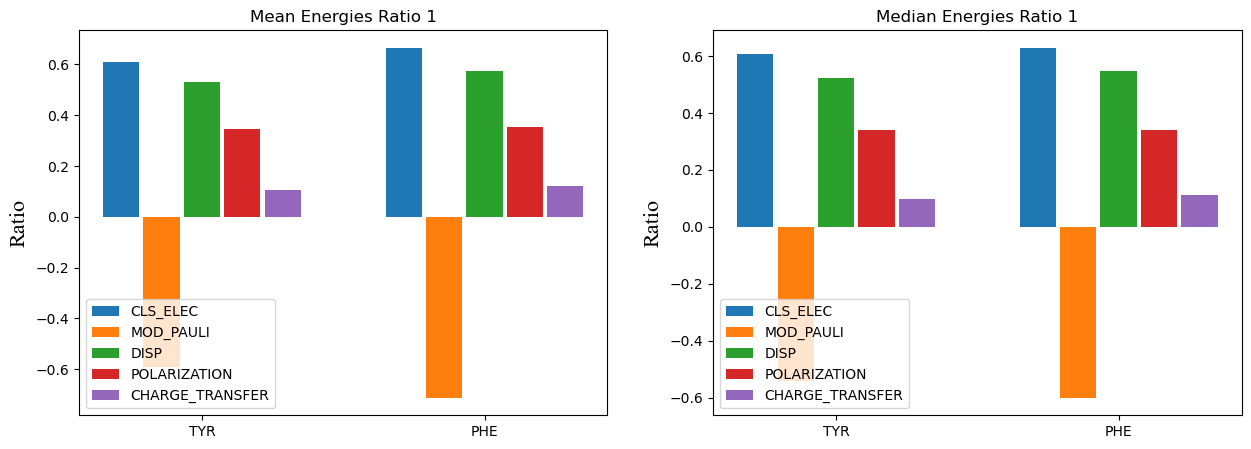

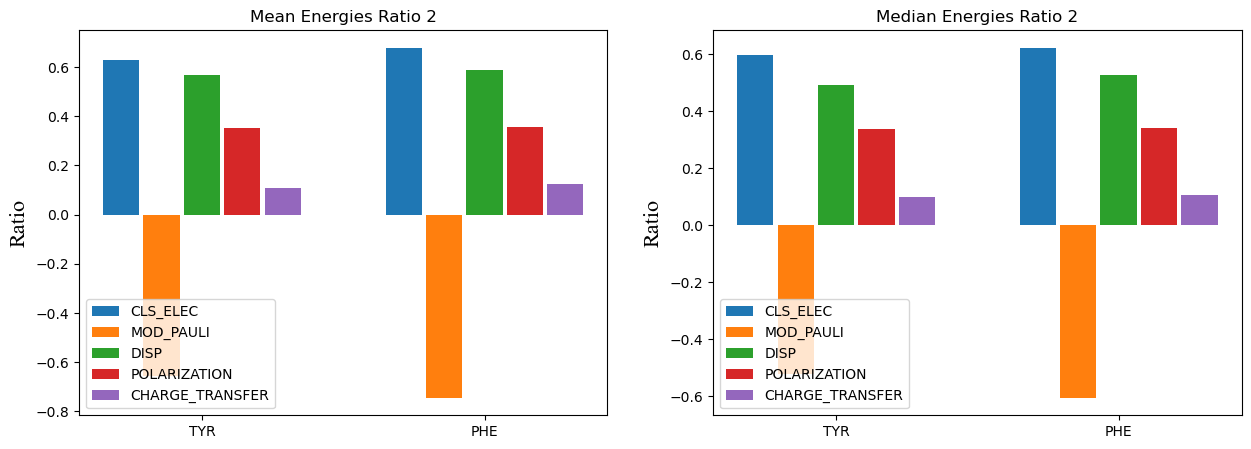

In [20]:
dfTYR = df.query("restype == 'TYR'")
dfPHE = df.query("restype == 'PHE'")

dfs = [dfTYR, dfPHE]
labels = ['TYR', 'PHE']

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot('bar', (labels, items), dfs, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=True)
axes[1].set_title('Median Energies')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot('bar', (labels, items), dfs, axes[0], ratio1=True)
axes[0].set_title('Mean Energies Ratio 1')
plot('bar', (labels, items), dfs, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies Ratio 1')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot('bar', (labels, items), dfs, axes[0], ratio2=True)
axes[0].set_title('Mean Energies Ratio 2')
plot('bar', (labels, items), dfs, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies Ratio 2')
plt.savefig("Visualizations/TYR_PH.slide.png")